# **Scoring docking models: can you beat the HADDOCK score?**

*Utrecht University Molecular Modelling courses from the [Bonvin lab](https://bonvinlab.org).*

**Docking** predicts the three-dimensional structure of a complex from the structures of its
components. Every docking program has to solve two problems:

* **sampling** — generate many candidate arrangements (*models*, or *poses*) of the partners;
* **scoring** — recognise, among all these models, the few that resemble the real complex.

Sampling is the easy part: a docking run produces hundreds or thousands of models, and usually some of
them are good. **Scoring is the hard part.** In a real prediction the true structure is unknown, so
the score is *all* you have to decide which model to believe.

This notebook looks at the scoring function of **HADDOCK** (High Ambiguity Driven DOCKing,
[wenmr.science.uu.nl/haddock2.4](https://wenmr.science.uu.nl/haddock2.4) and
[haddock3](https://github.com/haddocking/haddock3)):

> C. Dominguez, R. Boelens and A.M.J.J. Bonvin. **HADDOCK: a protein–protein docking approach based on
> biochemical or biophysical information.** *J. Am. Chem. Soc.* **125**, 1731–1737 (2003).

A HADDOCK run proceeds in stages. First, the partners are docked as **rigid bodies**, giving typically
1000 models. The best-scoring 200 are then **refined**: interface side chains and backbone are made
flexible and the models are finally refined (energy-minimised or briefly simulated in explicit solvent).
Every model is scored at every stage.

For the complexes studied here — one protein–protein complex in detail (IIA$^\text{Glc}$–HPr, PDB 1GGR), then ten more from a docking
benchmark — the experimental structure is known, so we can also measure **how good each model really is**.
That lets us ask how well the score does its job, and whether we can do better.

**What you will do**

1. Look at the terms that make up the HADDOCK score and at how each relates to model quality.
2. Rebuild the HADDOCK score from its terms (Exercise 1).
3. Measure how well it ranks the models — correlation, top-1/5/10, CAPRI classes (Exercise 2).
4. Compare rigid-body and refined models.
5. Try to **beat the HADDOCK score** with your own weights (Exercise 3), let the computer search,
   and check honestly whether the improvement is real.
6. Find out whether your improved score also works for **ten other complexes** from a docking
   benchmark (Exercise 4).

The follow-up notebook, **`Docking-scoring-optimisation`**, asks whether normalising the terms or
machine learning does better, and how a scoring function should really be optimised.

> **Solutions version — for instructors / checking only.** Every exercise is filled in with
> its worked solution and the solution blocks are unfolded, so all figures and numbers can be
> compared with the solution text. The student version is `Notebooks/Docking-scoring.ipynb`.

---
## **1. Theory**

### The HADDOCK score

The HADDOCK score of a model is a **weighted sum** of a few energy terms, computed between the two
partners (only intermolecular contributions count):

$$S \;=\; w_\text{vdW}\,E_\text{vdW} \;+\; w_\text{elec}\,E_\text{elec} \;+\; w_\text{desolv}\,E_\text{desolv}
\;+\; w_\text{AIR}\,E_\text{AIR} \;+\; w_\text{BSA}\,\text{BSA}$$

| term | what it measures | good model |
|---|---|---|
| $E_\text{vdW}$ (`vdw`) | van der Waals energy, the Lennard-Jones $4\varepsilon[(\sigma/r)^{12}-(\sigma/r)^6]$ summed over atom pairs across the interface (kcal/mol) | negative: tight packing. Large and positive: **clashes** |
| $E_\text{elec}$ (`elec`) | electrostatic (Coulomb) energy between the partners (kcal/mol) | negative: complementary charges |
| $E_\text{desolv}$ (`desolv`) | empirical **desolvation** energy: the free-energy change of taking the interface atoms out of water, from atomic solvation parameters (kcal/mol) | negative: burying hydrophobic surface |
| $E_\text{AIR}$ (`air`) | restraint energy: how much the model **violates the ambiguous interaction restraints** (AIRs), the experimental or predicted information that drives HADDOCK | 0 = all restraints satisfied |
| BSA (`bsa`) | **buried surface area**, the solvent-accessible surface hidden in the interface (Å²) | large interface |

**The lower the score, the better the model.** The weights differ between stages. For
**protein–protein** docking they are:

| weight | rigid body | final refinement |
|---|---|---|
| $w_\text{vdW}$ | 0.01 | 1.0 |
| $w_\text{elec}$ | 1.0 | 0.2 |
| $w_\text{desolv}$ | 1.0 | 1.0 |
| $w_\text{AIR}$ | 0.01 | 0.1 |
| $w_\text{BSA}$ | −0.01 | 0 |

The score mixes kcal/mol and Å², so it is **not** a physical free energy: it is an **empirical**
function, and its weights were tuned on benchmarks of complexes of known structure. That is exactly
what you will try to do yourself.

Why is the van der Waals weight a hundred times smaller in the rigid-body stage? Rigid partners
cannot move their side chains out of each other's way, so even a correct pose usually has a few
**clashes**: a large, positive $E_\text{vdW}$. With full weight, these clashes would push correct
poses down the ranking.

### How good is a model?

Each model is compared with the experimental structure of the complex:

* **i-RMSD** (interface RMSD): the root-mean-square deviation of the backbone atoms of the **interface
  residues**, after superimposing them on the reference (Å). Lower is better.
* **L-RMSD** (ligand RMSD): the RMSD of the smaller partner after superimposing the larger one (Å).
* **$F_\text{nat}$**: the fraction of the native residue–residue contacts that the model reproduces.
* **DockQ** combines all three into one continuous number between 0 and 1 (1 = identical to the reference):

$$\text{DockQ} \;=\; \frac13\left[\,F_\text{nat} \;+\; \frac{1}{1 + (\text{i-RMSD}/1.5\ \text{Å})^2}
\;+\; \frac{1}{1 + (\text{L-RMSD}/8.5\ \text{Å})^2}\,\right]$$

The blind docking experiment **CAPRI** (Critical Assessment of PRedicted Interactions) sorts models into
quality classes. In terms of DockQ:

| CAPRI class | DockQ | roughly, i-RMSD |
|---|---|---|
| **high** | ≥ 0.80 | ≤ 1 Å |
| **medium** | 0.49 – 0.80 | ≤ 2 Å |
| **acceptable** | 0.23 – 0.49 | ≤ 4 Å |
| **incorrect** | < 0.23 | > 4 Å |

### How good is a scoring function?

There are two different questions:

1. **Does the score follow the quality overall?** Measured by a **correlation coefficient** between
   score and DockQ over all models. The **Pearson** $r$ uses the values themselves; the **Spearman**
   $\rho$ uses only their **ranks** (1st, 2nd, …), so it measures whether the *order* is right and is
   not thrown off by a few extreme values. Because a *lower* score means a *better* model, a good
   scoring function has a strongly **negative** correlation with DockQ.
2. **Is the top of the list good?** In practice nobody looks at model number 600: one looks at the
   **top 1, 5 or 10**. A docking run is called a **success** at top $N$ if at least one of the $N$
   best-scored models is of acceptable quality or better (and similarly for medium and high).

3. **How does the quality depend on how many models you look at?** The **top-N curve** shows the mean
   DockQ of the $N$ best-scored models as a function of $N$. A perfect scoring function puts the best
   model first, so its curve starts at the highest DockQ in the set and only goes down.

To summarise the top of the curve in one number that rewards putting the **best models first**, we use the
**ranking quality**

$$\text{RQ}_{10} \;=\; \frac{1}{10}\sum_{N=1}^{10}\ \big\langle \text{DockQ} \big\rangle_{\text{top }N}$$

the average, over $N = 1 \ldots 10$, of the mean DockQ of the top $N$. The first-ranked model takes part in
all ten averages, the tenth only in the last one: $\text{RQ}_{10}$ weighs rank 1 most. It is the main
criterion in this notebook. A strong correlation is nice, but **what matters is the top of the list.**
These questions do **not** always have the same answer — you will see why.

## **Showing and hiding the code**

The Python that only draws figures is a means to an end, so **those cells start collapsed**: you
see the figure, not the matplotlib that made it. Nothing is disabled — a collapsed cell runs
exactly like an open one. The cells you need to read or edit are left open.

* **One cell:** click the blue **collapser bar** just left of it (or *View → Collapse Selected Code*).
* **All of them:** *View → Collapse All Code* / *Expand All Code*.

---
## **2. Imports**

Only **numpy** and **matplotlib** are needed; the cell installs them if missing, so the notebook
also runs on Google Colab and in the browser (JupyterLite).

In [1]:
# --- Install required packages (works locally, on Colab, and on JupyterLite) ---
%pip install -q matplotlib numpy

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys, warnings
if sys.platform == "emscripten":   # JupyterLite: its matplotlib build warns on every text label
    warnings.filterwarnings("ignore", message=r"The \w+ parameter as float was deprecated")
%matplotlib inline

# the five terms of the HADDOCK score, in a fixed order, and how to label them in figures
TERMS = ["vdw", "elec", "desolv", "air", "bsa"]
LABEL = {"vdw": "$E_\\mathrm{vdW}$ (kcal/mol)", "elec": "$E_\\mathrm{elec}$ (kcal/mol)",
         "desolv": "$E_\\mathrm{desolv}$ (kcal/mol)", "air": "$E_\\mathrm{AIR}$ (kcal/mol)",
         "bsa": "BSA (Å$^2$)", "score": "HADDOCK score", "dockq": "DockQ"}

# one fixed colour per CAPRI class (used in every figure)
CLASS_NAMES = ["incorrect", "acceptable", "medium", "high"]
CLASS_COLOR = ["#b9b9b9", "#eda100", "#2a78d6", "#1baf7a"]
C_RIGID, C_REF = "#eb6834", "#1c5cab"           # rigid-body / refined models
C_HADDOCK, C_YOU = "#4a4a4a", "#d55181"         # HADDOCK score / your score

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6,
})


def works(f, *args):
    """True once f(*args) returns real numbers instead of the NaN placeholder."""
    try:
        return bool(np.all(np.isfinite(np.asarray(f(*args), dtype=float))))
    except Exception:
        return False

def show_wide(text):
    """Show printed text without wrapping long lines: a wide table gets a horizontal scroll bar."""
    from html import escape
    from IPython.display import display
    style = ("white-space: pre; overflow-x: auto; margin: 0 0 1em 0; line-height: 1.3; "
             "font-family: var(--jp-code-font-family, monospace); font-size: var(--jp-code-font-size, 13px);")
    display({"text/html": f'<pre style="{style}">{escape(text)}</pre>', "text/plain": text}, raw=True)

---
## **Python you will need**

You do not need to be a Python expert for the exercises: each one needs only a few lines, and the
code cells contain step-by-step hints. These are the building blocks — run the cell below to see
each one in action, and come back here when a hint mentions one of them.

| what | example | result |
|---|---|---|
| a **dictionary** maps names to values | `w = {"vdw": 0.01, "elec": 1.0}` | |
| look a value up by its name | `w["elec"]` | `1.0` |
| loop over a list of names | `for term in ["vdw", "elec"]:` | |
| a data set is a dictionary of numpy **arrays**, one value per model | `d["dockq"]` | all DockQ values |
| arithmetic works on whole arrays, element by element | `0.01 * d["vdw"] + 1.0 * d["elec"]` | one number per model |
| add up in a loop | `total = 0` … `total = total + x` | |
| the **order** that sorts an array, lowest first | `np.argsort([3.0, -1.0, 2.0])` | `[1, 2, 0]` |
| put an array in that order | `y[order]` | |
| the first `n` elements | `y[:n]` | |
| mean, standard deviation | `np.mean(x)`, `np.std(x)` | |
| count the elements that satisfy a condition | `np.sum(y >= 0.23)` | |
| correlation coefficient of two arrays | `np.corrcoef(x, y)[0, 1]` | a number between −1 and 1 |
| copy a dictionary (so the original is left alone) | `z = dict(d)` | |

A **function** takes inputs, computes something and hands it back with `return`:

```python
def weighted_sum(a, b, wa, wb):
    return wa * a + wb * b
```

In [2]:
w = {"vdw": 0.01, "elec": 1.0}
print('w["elec"]                 =', w["elec"])
for term in ["vdw", "elec"]:
    print("  loop:", term, "has weight", w[term])

x = np.array([3.0, -1.0, 2.0])
y = np.array([0.1, 0.9, 0.4])
order = np.argsort(x)
print("np.argsort(x)             =", order, "  (x[1] = -1 is the lowest)")
print("y[order]                  =", y[order])
print("y[order][:2]              =", y[order][:2])
print("np.mean(y), np.std(y)     =", round(np.mean(y), 3), round(np.std(y), 3))
print("np.sum(y >= 0.23)         =", np.sum(y >= 0.23))
print("np.corrcoef(x, y)[0, 1]   =", round(np.corrcoef(x, y)[0, 1], 3))
total = 0
for v in [1, 2, 3]:
    total = total + 10 * v
print("loop + add                =", total)

w["elec"]                 = 1.0
  loop: vdw has weight 0.01
  loop: elec has weight 1.0
np.argsort(x)             = [1 2 0]   (x[1] = -1 is the lowest)
y[order]                  = [0.9 0.4 0.1]
y[order][:2]              = [0.9 0.4]
np.mean(y), np.std(y)     = 0.467 0.33
np.sum(y >= 0.23)         = 2
np.corrcoef(x, y)[0, 1]   = -0.991
loop + add                = 60


---
## **3. The data**

The data are in the folder `scoring-data`. Sections 4–11 use **one protein–protein complex**, the case
study: **enzyme IIA$^\text{Glc}$ with the phosphocarrier protein HPr** of the *E. coli* sugar
phosphotransferase system (PDB [1GGR](https://www.rcsb.org/structure/1GGR)), a transient signalling
complex whose NMR structure is the reference:

> G. Wang, J.M. Louis, M. Sondej, Y.-J. Seok, A. Peterkofsky and G.M. Clore. **Solution structure of the
> phosphoryl transfer complex between the signal transducing proteins HPr and IIA$^\text{Glucose}$ of the
> *Escherichia coli* phosphoenolpyruvate:sugar phosphotransferase system.** *EMBO J.* **19**, 5635–5649 (2000).

It was docked at two stages:

| file | stage | models |
|---|---|---|
| `protein-protein-data-rigidbody.csv` | rigid body | 1000 |
| `protein-protein-data-finalref.csv` | final refinement | 200 |

Each line is one model, **sorted by HADDOCK score** (best first), with its HADDOCK score, the five
terms, and the two quality measures **i-RMSD** and **DockQ**. Two more files, with ten other complexes,
are used in §10. The next cell finds the folder next to this notebook, or downloads the files from the
course repository when they are not there (e.g. on Colab).

In [3]:
import urllib.request

FILES = {"pp_rigid":    "protein-protein-data-rigidbody.csv",       # the case study (sections 4-9)
         "pp_refined":  "protein-protein-data-finalref.csv",
         "bm5_rigid":   "bm5-rigidbody.tsv",                        # ten benchmark complexes (section 10)
         "bm5_refined": "bm5-refined.tsv"}
URL = "https://raw.githubusercontent.com/haddocking/molmod-education/main/Notebooks/scoring-data/"

def find_data_dir():
    for d in (Path("scoring-data"), Path("Notebooks/scoring-data"), Path("../Notebooks/scoring-data")):
        if all((d / f).exists() for f in FILES.values()):
            return d
    d = Path("scoring-data")
    d.mkdir(exist_ok=True)
    for f in FILES.values():
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, d / f)
    return d

DATA_DIR = find_data_dir()
print("data folder:", DATA_DIR.resolve())

data folder: /Users/abonvin/haddock_git/molmod-education/Notebooks/scoring-data


Before writing code to read a file, **look at it**. Here are the first three lines of two of the
files, exactly as stored (`repr` shows the invisible characters):

In [4]:
for key in ("pp_rigid", "pp_refined"):
    print(FILES[key])
    with open(DATA_DIR / FILES[key], encoding="utf-8") as fh:
        for _ in range(3):
            print("   ", repr(fh.readline()))

protein-protein-data-rigidbody.csv
    '\ufeffHADDOCK-rank;score;irmsd;dockq;rmsd;air;bsa;desolv;elec;vdw\n'
    '1;-37.430;3.110;0.342;2.906;88.078;1.169.090;-14.514;-11.977;-12.911\n'
    '2;-36.117;2.735;0.367;2.508;9.332;1.143.430;-17.075;-7.470;-23.102\n'
protein-protein-data-finalref.csv
    '\ufeffHADDOCK-score;score;irmsd;dockq;air;bsa;desolv;elec;vdw\n'
    '1;-123.594;1.469;0.724;42.113;1.435.800;-15.725;-367.234;-38.634\n'
    '2;-121.842;2.118;0.565;13.756;1.433.120;-11.878;-419.226;-27.495\n'


These two files are a spreadsheet export, and they need some care:

* the columns are separated by **semicolons**; the file starts with an invisible **byte-order mark**
  (`﻿`) and the lines end in `\r\n` (Windows);
* the dot is used **twice**: as the decimal point *and* as a thousands separator. `1.169.090` is a
  buried surface of 1169.090 Å², `-11.977` is −11.977 kcal/mol. Every number has exactly **three
  decimals**, so the safe way to read one is to remove all dots and divide by 1000;
* the first column is the **rank** (1 = best score), although in three of the files its header says
  `HADDOCK-score`; the second column, `score`, is the actual score;
* the protein–protein rigid-body file has one extra column, `rmsd`, that we do not use.

The function below handles all of this and returns each file as a **dictionary of arrays**:
`d["dockq"]` holds the DockQ of every model, `d["vdw"]` its van der Waals energy, and so on.

In [5]:
def load_models(path):
    """Read one data file -> dict {column name: numpy array}, one value per model."""
    text = Path(path).read_text(encoding="utf-8-sig")          # 'utf-8-sig' drops the BOM
    lines = [line for line in text.splitlines() if line.strip()]
    names = ["rank"] + lines[0].split(";")[1:]                   # column 1 is the rank
    rows = []
    for line in lines[1:]:
        fields = line.split(";")
        # every number has 3 decimals: "1.169.090" -> 1169090 / 1000 = 1169.09
        rows.append([int(field.replace(".", "")) / 1000 for field in fields[1:]])
    values = np.array(rows)
    data = {"rank": np.arange(1, len(rows) + 1)}
    for j, name in enumerate(names[1:]):
        data[name] = values[:, j]
    return data


DATA = {key: load_models(DATA_DIR / FILES[key]) for key in ("pp_rigid", "pp_refined")}

print(f"{'data set':>11} {'models':>7} {'score range':>18} {'DockQ range':>14} "
      f"{'incorrect':>10} {'acceptable':>11} {'medium':>7} {'high':>5}")
for key, d in DATA.items():
    dq = d["dockq"]
    counts = [np.sum(dq < 0.23), np.sum((dq >= 0.23) & (dq < 0.49)),
              np.sum((dq >= 0.49) & (dq < 0.80)), np.sum(dq >= 0.80)]
    print(f"{key:>11} {len(dq):>7} {d['score'].min():>8.1f} to {d['score'].max():>6.1f} "
          f"{dq.min():>6.3f}-{dq.max():.3f} {counts[0]:>10} {counts[1]:>11} {counts[2]:>7} {counts[3]:>5}")

   data set  models        score range    DockQ range  incorrect  acceptable  medium  high
   pp_rigid    1000    -37.4 to    3.4  0.029-0.759        591         271     138     0
 pp_refined     200   -123.6 to  -30.2  0.081-0.854         37          54      96    13


The last four columns count the models in each **CAPRI class**. Keep this table in mind: it shows
how many good models there are to be found.

---
## **4. Protein–protein, rigid body: what do the score terms look like?**

First the **distribution** of each term over the 1000 rigid-body models. Each histogram is split by
CAPRI class, so you can see where the good models (coloured) sit among the incorrect ones (grey):

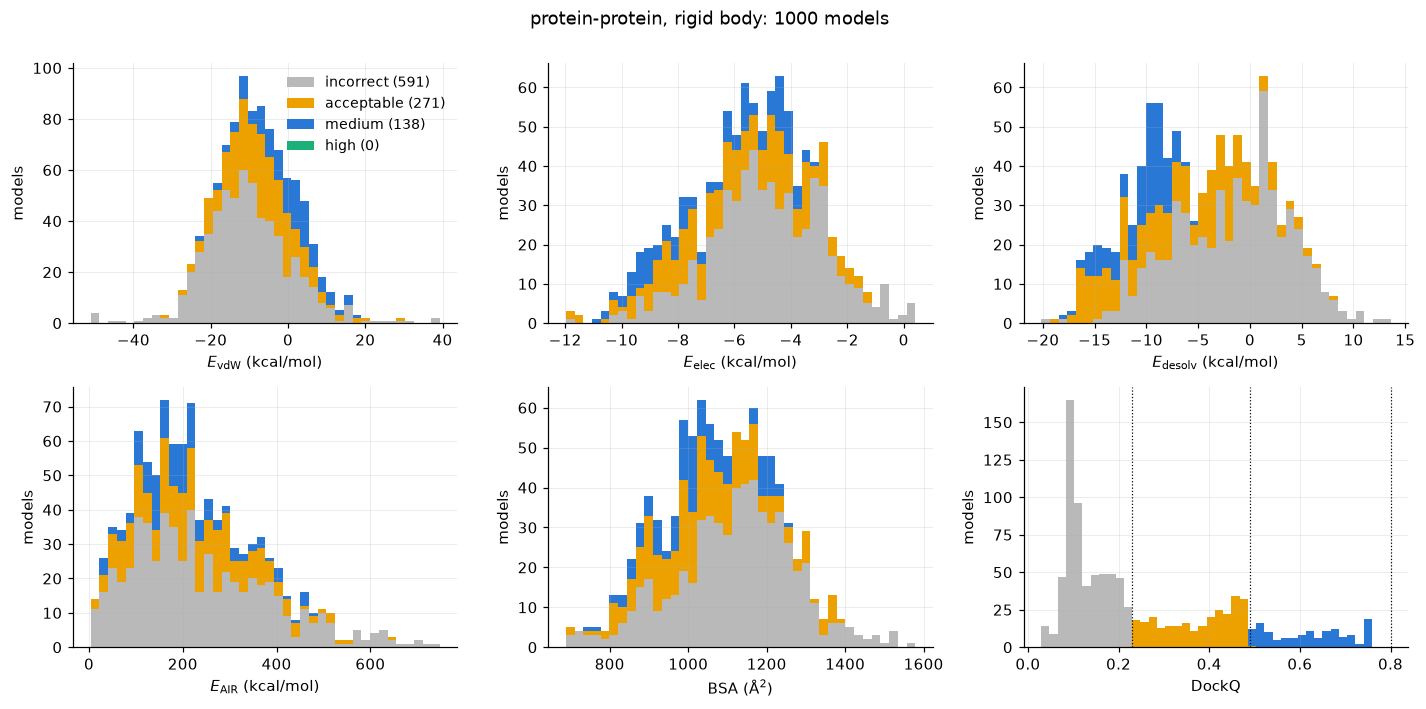

In [6]:
def class_of(dq):
    """CAPRI class of every model: 0 incorrect, 1 acceptable, 2 medium, 3 high."""
    dq = np.asarray(dq)
    return (dq >= 0.23).astype(int) + (dq >= 0.49) + (dq >= 0.80)


def class_histograms(d, keys, title, nbins=40):
    cls = class_of(d["dockq"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
    for ax, key in zip(axes.flat, keys):
        x = d[key]
        bins = np.linspace(x.min(), x.max(), nbins + 1)
        parts = [x[cls == c] for c in range(4)]
        ax.hist(parts, bins=bins, stacked=True, color=CLASS_COLOR,
                label=[f"{n} ({len(p)})" for n, p in zip(CLASS_NAMES, parts)])
        ax.set_xlabel(LABEL[key]); ax.set_ylabel("models")
        if key == "dockq":
            for t in (0.23, 0.49, 0.80):
                ax.axvline(t, color="k", lw=0.8, ls=":")
    axes.flat[0].legend(loc="upper right")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


class_histograms(DATA["pp_rigid"], TERMS + ["dockq"], "protein-protein, rigid body: 1000 models")

Now each term **against DockQ**, one dot per model. The title of each panel gives the Pearson $r$ and the
Spearman $\rho$ between that term and DockQ; the last panel is the HADDOCK score itself. The dotted
lines are the CAPRI class boundaries.

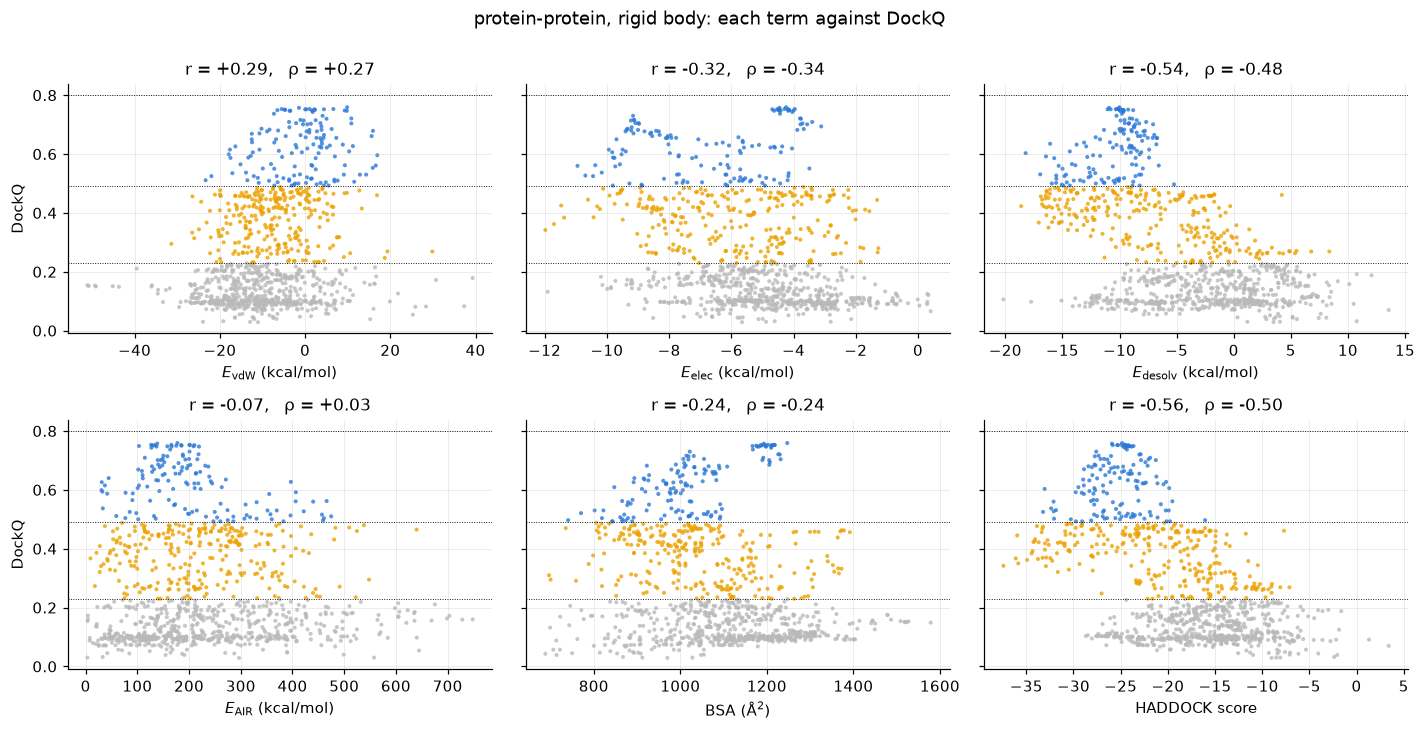

In [7]:
def avg_ranks(x):
    """Rank of every element (0 = lowest); tied values share the average of their ranks."""
    x = np.asarray(x, dtype=float)
    order = np.argsort(x, kind="stable")
    r = np.empty(len(x)); r[order] = np.arange(len(x))
    _, inverse, counts = np.unique(x, return_inverse=True, return_counts=True)
    return (np.bincount(inverse, weights=r) / counts)[inverse]

def pearson(x, y):
    return np.corrcoef(x, y)[0, 1]

def spearman(x, y):
    """Spearman rank correlation = Pearson correlation of the ranks."""
    return np.corrcoef(avg_ranks(x), avg_ranks(y))[0, 1]


def terms_vs_dockq(d, keys, title):
    cls = class_of(d["dockq"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharey=True)
    for ax, key in zip(axes.flat, keys):
        ax.scatter(d[key], d["dockq"], s=7, c=[CLASS_COLOR[c] for c in cls], alpha=0.8, lw=0)
        for t in (0.23, 0.49, 0.80):
            ax.axhline(t, color="k", lw=0.6, ls=":")
        ax.set_xlabel(LABEL[key])
        ax.set_title(f"r = {pearson(d[key], d['dockq']):+.2f},   ρ = {spearman(d[key], d['dockq']):+.2f}")
    for ax in axes[:, 0]:
        ax.set_ylabel("DockQ")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


terms_vs_dockq(DATA["pp_rigid"], TERMS + ["score"], "protein-protein, rigid body: each term against DockQ")

**Questions**

**(a)** Which terms are mostly negative (favourable) and which mostly positive? What does a positive
$E_\text{vdW}$ mean for a rigid-body model?

**(b)** $E_\text{AIR}$ spans a very wide range. What do models with a very large restraint energy have
in common?

**(c)** Which single term separates the good models from the incorrect ones best? Is that the term with
the strongest correlation?

**(d)** How strong is the correlation between the HADDOCK score and DockQ? Would you call the score a
good *predictor* of DockQ? Where in the score range are the best models?

<details open>
<summary><b>Section 4 — answers</b></summary>

**(a)** $E_\text{elec}$ and $E_\text{desolv}$ are mostly negative, BSA is by definition positive (it is an
area, given weight −0.01). $E_\text{vdW}$ ranges from about −50 to +40 kcal/mol: many rigid-body models
**clash**. That is why it has only weight 0.01 at this stage.

**(b)** $E_\text{AIR}$ ranges from 3 to 750 kcal/mol. The models with a large restraint energy are
almost all **incorrect**: they do not satisfy the information used to drive the docking.
They are also the reason why a plain average or standard deviation of this term is dominated by a few
models.

**(c)** $E_\text{desolv}$ has the strongest correlation ($r = -0.54$), followed by $E_\text{elec}$
($-0.32$); $E_\text{vdW}$ correlates *positively* ($+0.29$): in the rigid-body stage, the better models
clash *more*, because a correct interface is a tight one. $E_\text{AIR}$ hardly correlates with DockQ
at all, even though its extreme values flag bad models: a correlation coefficient summarises the
whole cloud, not its tail.

**(d)** $r = -0.56$, $\rho = -0.50$: a clear trend, but with a lot of scatter. At any given score,
DockQ varies by 0.3–0.5. The best models are among the lowest scores, but so are many acceptable ones,
and the very best model (DockQ 0.76) is not ranked first. The score is a **filter** rather than a
predictor of DockQ.
</details>

---
## **5. Exercise 1 — rebuild the HADDOCK score**

**(a)** Fill in the protein–protein weights of the table in §1 as two dictionaries, `W_RIGID` and
`W_REFINE` (keys `"vdw"`, `"elec"`, `"desolv"`, `"air"`, `"bsa"`). Mind the sign of the BSA weight.

**(b)** Write `haddock_score(d, w)`: given a data set `d` (a dictionary of arrays) and a dictionary of
weights `w`, return the score of **every** model, $S = \sum_\text{terms} w_\text{term}\,E_\text{term}$.

The self-check compares your score with the one in the files. If one weight is wrong it tries to
tell you which.

In [8]:
# ---------- Exercise 1: weights and score ----------
# (a) the protein-protein weights from the table in section 1 (replace every None by a number)
W_RIGID  = {"vdw": 0.01, "elec": 1.0, "desolv": 1.0, "air": 0.01, "bsa": -0.01}
W_REFINE = {"vdw": 1.0,  "elec": 0.2, "desolv": 1.0, "air": 0.1,  "bsa": 0.0}

def haddock_score(d, w):
    """(b) HADDOCK score of every model in data set d (dict of arrays), with weights w (dict)."""
    total = 0
    for term in TERMS:
        total = total + w[term] * d[term]
    return total

In [9]:
# ---------- self-check ----------
def check_weights(name, d, w, tol=0.01):
    """Compare haddock_score(d, w) with the score in the file; diagnose a single wrong weight."""
    if not isinstance(w, dict) or sorted(w) != sorted(TERMS):
        print(f"    {name}: the weights must be a dict with keys {TERMS}")
        return False
    if any(not isinstance(v, (int, float)) for v in w.values()):
        print(f"    {name}: not yet: replace every None by a number")
        return False
    if not works(haddock_score, d, w):
        print(f"    {name}: not yet: complete haddock_score()")
        return False
    diff = np.asarray(haddock_score(d, w), dtype=float) - d["score"]
    if np.shape(diff) != np.shape(d["score"]):
        print(f"    {name}: haddock_score() should return one value per model")
        return False
    if np.max(np.abs(diff)) < tol:
        print(f"    {name}: largest difference with the file {np.max(np.abs(diff)):.4f}   OK")
        return True
    for term in TERMS:                         # is the difference explained by one term alone?
        k = np.sum(diff * d[term]) / np.sum(d[term] ** 2)
        if np.max(np.abs(diff - k * d[term])) < tol:
            print(f"    {name}: off by up to {np.max(np.abs(diff)):.2f}; the weight of '{term}' is "
                  f"{w[term]:g} but the file needs {w[term] - k:.3g}")
            return False
    print(f"    {name}: off by up to {np.max(np.abs(diff)):.2f}: more than one weight differs "
          "(or the sum is not right)")
    return False


print("(a)+(b) protein-protein")
ok_rigid = check_weights("rigid body,  W_RIGID ", DATA["pp_rigid"], W_RIGID)
ok_refine = check_weights("refinement,  W_REFINE", DATA["pp_refined"], W_REFINE)
ex1_ok = ok_rigid and ok_refine

(a)+(b) protein-protein
    rigid body,  W_RIGID : largest difference with the file 0.0015   OK
    refinement,  W_REFINE: largest difference with the file 0.0013   OK


<details open>
<summary><b>Exercise 1 — worked solution</b></summary>

```python
W_RIGID  = {"vdw": 0.01, "elec": 1.0, "desolv": 1.0, "air": 0.01, "bsa": -0.01}
W_REFINE = {"vdw": 1.0,  "elec": 0.2, "desolv": 1.0, "air": 0.1,  "bsa": 0.0}

def haddock_score(d, w):
    total = 0
    for term in TERMS:
        total = total + w[term] * d[term]
    return total
```

Both reproduce the scores in the files to within 0.002 (the rounding of the three-decimal data).
For example, the best rigid-body model has
$0.01\times(-12.91) + (-11.98) + (-14.51) + 0.01\times 88.08 - 0.01\times 1169.09 = -37.43$.
Note how much the BSA contributes ($-11.7$) compared with $E_\text{vdW}$ ($-0.13$).
</details>

---
## **6. Exercise 2 — does the score find the good models?**

To judge a ranking, you need the quality of the models **in the order of their score**.

**(a)** Write `top_n(score, dockq, n)`: given the scores and DockQ values of all models (two arrays of
equal length), return the DockQ values of the **`n` best-scored models, best first**. Remember: the
*lowest* score is the best.

The self-check uses a small made-up example; the cells after it then evaluate the HADDOCK score.

In [10]:
# ---------- Exercise 2: complete the function ----------
def top_n(score, dockq, n):
    """(a) DockQ of the n models with the lowest (best) score, best first."""
    order = np.argsort(score, kind="stable")
    return np.asarray(dockq)[order][:n]

In [11]:
# ---------- self-check ----------
test_score = np.array([3.0, -1.0, 2.0, 0.0, 1.0])
test_dockq = np.array([0.10, 0.50, 0.20, 0.90, 0.30])
print("scores", test_score, " DockQ", test_dockq)
ex2_ok = False
if works(top_n, test_score, test_dockq, 2):
    got = np.asarray(top_n(test_score, test_dockq, 2), dtype=float)
    diagnosis = [([0.5, 0.9], "OK"),
                 ([0.1, 0.2], "<- these are the WORST two: for the HADDOCK score, lower is better"),
                 ([1.0, 3.0], "<- these are model indices: return the DockQ values of those models"),
                 ([0.9, 0.5], "<- sorted by DockQ: in a real prediction you do not know DockQ, sort by score"),
                 ([-1.0, 0.0], "<- these are the scores: return the DockQ values")]
    if got.shape != (2,):
        print(f"    top_n(..., 2) returned {got}: it should return exactly 2 values")
    else:
        msg = next((m for want, m in diagnosis if np.allclose(got, want)), "<- expected [0.5 0.9]")
        print(f"    top 2 -> {got}   {msg}")
        ex2_ok = msg == "OK"
        if ex2_ok:
            print(f"    top 5 -> {np.asarray(top_n(test_score, test_dockq, 5))}")
else:
    print("    not yet: replace the placeholder")

scores [ 3. -1.  2.  0.  1.]  DockQ [0.1 0.5 0.2 0.9 0.3]
    top 2 -> [0.5 0.9]   OK
    top 5 -> [0.5 0.9 0.3 0.2 0.1]


With `top_n` in place, the next (collapsed) cell defines a few tools used in the rest of the notebook:
`evaluate(score, dockq)` collects the numbers that describe a ranking, and `print_table` prints them for
several scoring functions side by side:

* `r`, `rho` — Pearson and Spearman correlation with DockQ (more negative = better);
* `top1` — DockQ of the best-scored model;  `best5`, `best10` — the best DockQ among the top 5 / 10;
* `mean10` — the mean DockQ of the top 10;  `RQ10` — the ranking quality of §1 (higher = better);
* `top1 / top5 / top10` *class* — the best CAPRI class found among the top 1, 5 and 10
  (`H` high, `M` medium, `A` acceptable, `-` none).

In [12]:
def rank_quality(score, dockq, nmax=10):
    """RQ_nmax: the mean DockQ of the top N, averaged over N = 1 ... nmax (rank 1 counts most)."""
    ranked = top_n(score, dockq, nmax)
    return np.mean(np.cumsum(ranked) / np.arange(1, nmax + 1))


def evaluate(score, dockq):
    """Numbers that describe how well `score` ranks the models (lower score = better)."""
    ranked = top_n(score, dockq, len(dockq))
    best_class = lambda n: "-AMH"[class_of(ranked[:n]).max()]
    return {"r": pearson(score, dockq), "rho": spearman(score, dockq),
            "top1": ranked[0], "best5": ranked[:5].max(), "best10": ranked[:10].max(),
            "mean10": ranked[:10].mean(), "rq10": rank_quality(score, dockq),
            "class": best_class(1) + " " + best_class(5) + " " + best_class(10)}


def print_table(rows, title=""):
    """rows: list of (label, score array, dockq array)."""
    out = []
    if title:
        out.append(title)
    out.append(f"{'':32} {'r':>6} {'rho':>6} {'top1':>6} {'best5':>6} {'best10':>6} {'mean10':>7} {'RQ10':>6}"
               "   class top1/5/10")
    for label, s, dq in rows:
        e = evaluate(s, dq)
        out.append(f"{label:32} {e['r']:>+6.2f} {e['rho']:>+6.2f} {e['top1']:>6.3f} {e['best5']:>6.3f} "
                   f"{e['best10']:>6.3f} {e['mean10']:>7.3f} {e['rq10']:>6.3f}     {e['class']}")
    out.append("")
    show_wide("\n".join(out))


def topn_curves(ax, panels, nmax=50):
    """Top-N curves: mean DockQ of the top N (solid) and best DockQ within the top N (dashed)."""
    cols = [C_HADDOCK, C_YOU, C_REF, C_RIGID, "#1baf7a", "#eda100"]
    for (label, s, dq), col in zip(panels, cols):
        ranked = top_n(s, dq, nmax)
        n = np.arange(1, len(ranked) + 1)
        ax.plot(n, np.cumsum(ranked) / n, "-", color=col, label=f"{label}: mean of top N")
        ax.plot(n, np.maximum.accumulate(ranked), "--", color=col, lw=1, label=f"{label}: best in top N")
    for t in (0.23, 0.49, 0.80):
        ax.axhline(t, color="k", lw=0.6, ls=":")
    ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50]); ax.set_xticklabels([1, 2, 5, 10, 20, 50])
    ax.set_xlabel("N (number of top-ranked models)"); ax.set_ylabel("DockQ")
    ax.set_title("top-N curves"); ax.legend(loc="lower left", fontsize=7)


def ranking_figure(panels, title):
    """panels: list of (label, score, dockq). Left: score vs DockQ (top 10 ringed); right: DockQ by rank."""
    fig, axes = plt.subplots(1, len(panels) + 1, figsize=(5.2 * (len(panels) + 1), 4.2))
    for ax, (label, s, dq) in zip(axes, panels):
        cls = class_of(dq)
        top = np.argsort(s, kind="stable")[:10]
        ax.scatter(s, dq, s=7, c=[CLASS_COLOR[c] for c in cls], alpha=0.8, lw=0)
        ax.scatter(s[top], dq[top], s=50, facecolors="none", edgecolors="k", lw=1, label="top 10")
        for t in (0.23, 0.49, 0.80):
            ax.axhline(t, color="k", lw=0.6, ls=":")
        ax.set_xlabel(label); ax.set_ylabel("DockQ"); ax.legend(loc="upper right")
    topn_curves(axes[-1], [(label, s, dq) for label, s, dq in panels])
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

**(b)** Run the next cell. It shows the HADDOCK score against DockQ with the top 10 ringed, the
**top-N curves**, and a table that compares the HADDOCK score with **each term used on its
own** as a score (with the sign it has in the HADDOCK score, so that lower is always better).

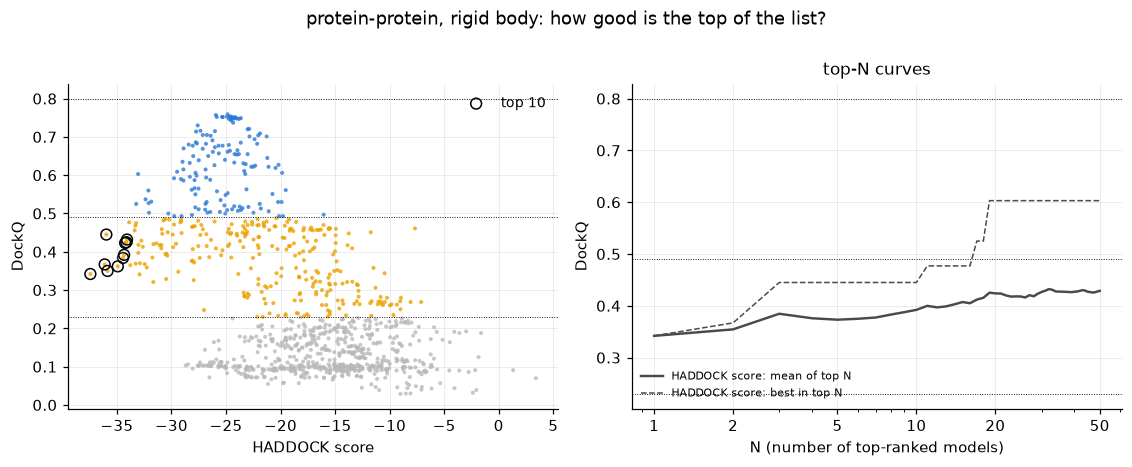

protein-protein, rigid body (1000 models)
                                      r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
vdw alone                         +0.29  +0.27  0.154  0.154  0.211   0.155  0.155     - - -
elec alone                        -0.32  -0.34  0.342  0.425  0.560   0.409  0.348     A A M
desolv alone                      -0.54  -0.48  0.106  0.603  0.603   0.388  0.325     - M M
air alone                         -0.07  +0.03  0.030  0.173  0.367   0.156  0.122     - - A
-bsa alone                        +0.24  +0.24  0.149  0.153  0.175   0.156  0.153     - - -

best model in the set: DockQ 0.759, ranked 186 by the HADDOCK score


In [13]:
if not ex2_ok:
    print("Not yet: top_n() must pass the self-check above.")
else:
    d = DATA["pp_rigid"]
    ranking_figure([("HADDOCK score", d["score"], d["dockq"])],
                   "protein-protein, rigid body: how good is the top of the list?")
    sign = {"vdw": 1, "elec": 1, "desolv": 1, "air": 1, "bsa": -1}
    rows = [("HADDOCK score", d["score"], d["dockq"])]
    rows += [(f"{'-' if sign[t] < 0 else ''}{t} alone", sign[t] * d[t], d["dockq"]) for t in TERMS]
    print_table(rows, "protein-protein, rigid body (1000 models)")
    print(f"best model in the set: DockQ {d['dockq'].max():.3f}, ranked {d['rank'][np.argmax(d['dockq'])]} "
          f"by the HADDOCK score")

**(c)** Is the rigid-body docking a success at top 1? At top 10? What CAPRI quality is the best model in
the top 10, and what quality was available in the whole set?

**(d)** Which single term gives the best **correlation** with DockQ? Is it also the term that gives the
best **top 10**? What does that tell you about using a correlation coefficient to judge a scoring function?

**(e)** Can any term on its own replace the HADDOCK score?

<details open>
<summary><b>Exercise 2 — worked solution</b></summary>

```python
def top_n(score, dockq, n):
    order = np.argsort(score)
    return dockq[order][:n]
```

| | $r$ | $\rho$ | top1 | best10 | mean10 | RQ10 | class top 1/5/10 |
|---|---|---|---|---|---|---|---|
| HADDOCK score | −0.56 | −0.50 | 0.342 | 0.445 | 0.392 | 0.375 | A A A |
| `desolv` alone | −0.54 | −0.48 | 0.106 | 0.603 | 0.388 | 0.325 | - M M |
| `elec` alone | −0.32 | −0.34 | 0.342 | 0.560 | 0.409 | 0.348 | A A M |

**(c)** Yes — an acceptable model is ranked first, and all of the top 10 are acceptable. But **none of the
top 10 is of medium quality**, although the set contains 138 medium models (best DockQ 0.76, ranked
186th). The rigid-body score finds the right *region*, not the best models.

**(d)** $E_\text{desolv}$ correlates almost as well as the full score, but ranks an *incorrect* model
first. $E_\text{elec}$ correlates much worse ($r=-0.32$) yet gives a top 10 at least as good as the
HADDOCK score (mean DockQ 0.409 against 0.392, a medium model within the top 10). A correlation coefficient weighs all 1000 models equally — most of them are bad models
nobody will ever look at — while what matters is the order at the very top.

**(e)** No single term is as reliable: each fails somewhere (top 1, top 5 or the correlation). Each
term catches a different kind of error, which is why the score combines them.
</details>

---
## **7. After refinement**

The 200 best rigid-body models were refined with flexible interfaces. How did that change the terms
and the quality? Below, the distributions before (rigid body, 1000 models) and after (refined, 200
models). Each histogram is normalised to an area of 1 so that the two sets can be compared.

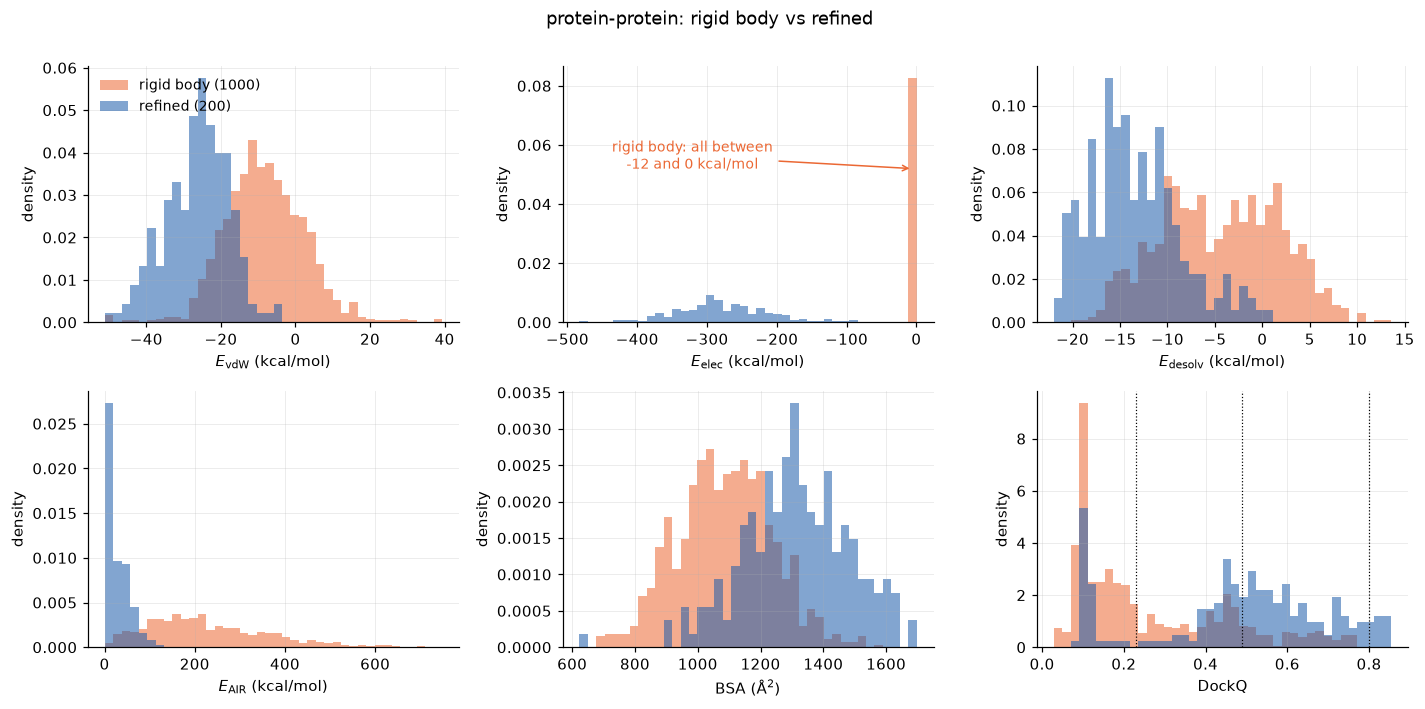

In [14]:
d0, d1 = DATA["pp_rigid"], DATA["pp_refined"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, key in zip(axes.flat, TERMS + ["dockq"]):
    lo = min(d0[key].min(), d1[key].min()); hi = max(d0[key].max(), d1[key].max())
    bins = np.linspace(lo, hi, 41)
    ax.hist(d0[key], bins=bins, density=True, color=C_RIGID, alpha=0.55, label="rigid body (1000)")
    ax.hist(d1[key], bins=bins, density=True, color=C_REF, alpha=0.55, label="refined (200)")
    ax.set_xlabel(LABEL[key]); ax.set_ylabel("density")
    if key == "dockq":
        for t in (0.23, 0.49, 0.80):
            ax.axvline(t, color="k", lw=0.8, ls=":")
    if key == "elec":
        ax.annotate(f"rigid body: all between\n{d0[key].min():.0f} and {d0[key].max():.0f} kcal/mol",
                    xy=(d0[key].mean(), 0.6), xycoords=("data", "axes fraction"),
                    xytext=(0.35, 0.6), textcoords="axes fraction", ha="center",
                    arrowprops=dict(arrowstyle="->", color=C_RIGID), color=C_RIGID, fontsize=9)
axes.flat[0].legend(loc="upper left")
fig.suptitle("protein-protein: rigid body vs refined", y=1.0)
plt.tight_layout(); plt.show()

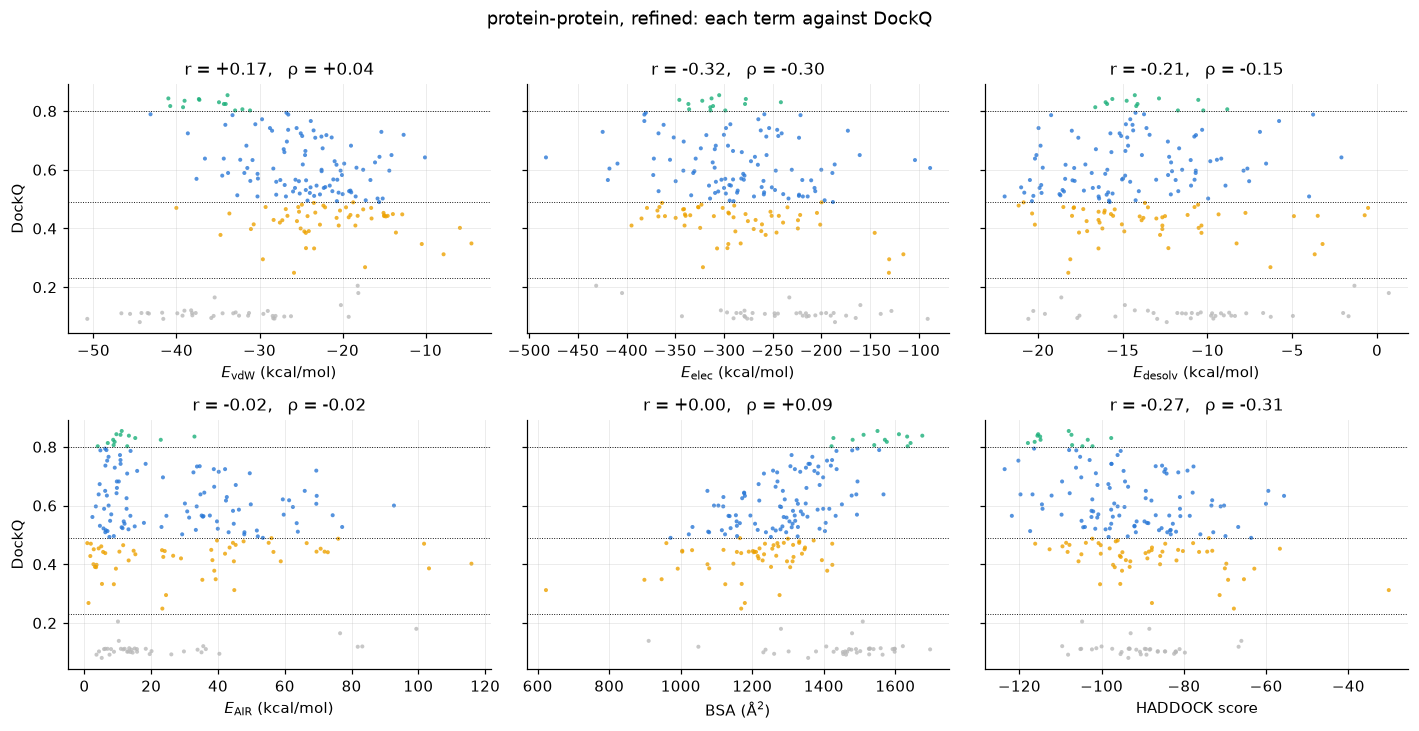

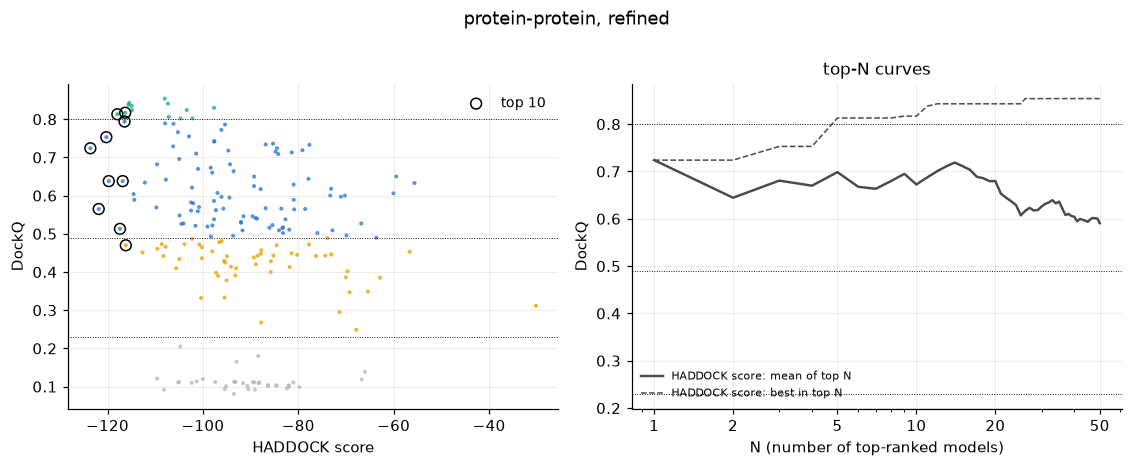

protein-protein, refined (200 models)
                                      r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score (refine weights)    -0.27  -0.31  0.724  0.813  0.817   0.672  0.680     M H H
rigid-body weights                -0.34  -0.32  0.642  0.729  0.794   0.518  0.522     M M M

protein-protein, rigid body (1000 models)
                                      r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score (rigid weights)     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
refinement weights                -0.07  +0.00  0.367  0.367  0.511   0.290  0.245     A A M

In [15]:
d = DATA["pp_refined"]
terms_vs_dockq(d, TERMS + ["score"], "protein-protein, refined: each term against DockQ")
if not ex2_ok:
    print("Not yet: top_n() (Exercise 2) is needed for the ranking analysis.")
else:
    ranking_figure([("HADDOCK score", d["score"], d["dockq"])], "protein-protein, refined")
    rows = [("HADDOCK score (refine weights)", d["score"], d["dockq"])]
    if ex1_ok:
        rows.append(("rigid-body weights", haddock_score(d, W_RIGID), d["dockq"]))
        d0 = DATA["pp_rigid"]
        print_table(rows, "protein-protein, refined (200 models)")
        print_table([("HADDOCK score (rigid weights)", d0["score"], d0["dockq"]),
                     ("refinement weights", haddock_score(d0, W_REFINE), d0["dockq"])],
                    "protein-protein, rigid body (1000 models)")
    else:
        print_table(rows, "protein-protein, refined (200 models)")
        print("(complete Exercise 1 to also see each stage scored with the other stage's weights)")

**Questions**

**(a)** What did refinement do to $E_\text{vdW}$ and $E_\text{elec}$? Why?

**(b)** How did the quality change? How many high-quality models are there now?

**(c)** The correlation between score and DockQ is **weaker** after refinement than before, yet the top
of the list is **much better**. How can both be true? *(Hint: which models are in the refined set, and
what is the spread of their DockQ?)*

**(d)** What happens when you score each stage with the *other* stage's weights? Why do the stages need
different weights?

<details open>
<summary><b>Section 7 — answers</b></summary>

**(a)** The clashes are gone: $E_\text{vdW}$ is negative for every refined model (−51 to −4 kcal/mol,
against up to +39 in rigid body), because the flexible interfaces can relax. $E_\text{elec}$ becomes
much more negative (around −280 kcal/mol instead of −5): flexible side chains form salt bridges and
hydrogen bonds. Refinement also uses a more complete electrostatics model than the fast rigid-body
stage.

**(b)** Rigid body: 409 acceptable-or-better models out of 1000, 138 medium, **0 high**. Refined: 163 of
200 acceptable or better, 109 medium and **13 high**.

**(c)** The refined set only contains the 200 best rigid-body models, most of which are already
acceptable: the DockQ range is narrower and most models are "good", so there is less to correlate
(the same happens with any selection, e.g. the correlation between height and basketball skill
*within* a professional team is weak). Meanwhile, the score is better at recognising the **best**
models: the top 10 are all at least medium quality and 2 are high.

**(d)** Refinement weights on rigid-body models put full weight on the clashes: the ranking collapses
(the top 10 is much worse). Rigid-body weights on refined models ignore the now meaningful van der
Waals packing and over-weight $E_\text{elec}$; the top 10 also gets worse. A scoring function is tuned
for the kind of models it has to rank.
</details>

---
## **8. Exercise 3 — can you beat the HADDOCK score?**

Now it is your turn to design a scoring function. Choose your own weights for the five terms, for the
**rigid-body** models (`MY_WEIGHTS_RIGID`) and for the **refined** models (`MY_WEIGHTS_REFINE`). They start
as copies of the HADDOCK weights; change them, re-run the next two cells, and watch the table.

**The goal:** a better **top of the list** than the HADDOCK score. Use the ranking quality `RQ10` as the main
criterion, and keep an eye on `top1`, `mean10`, the CAPRI classes and the top-N curves. Ideas to try:

* use what you learnt in §4 and §6 about which terms carry information, and in which direction;
* switch a term off (weight 0), or make one much more important;
* remember that a weight only matters **relative to the spread** of its term: 0.01 × BSA (spread
  ≈ 1000 Å²) is not small.

In [16]:
# ---------- Exercise 3: your weights (start from the HADDOCK ones and change them) ----------
MY_WEIGHTS_RIGID  = {"vdw": 0.0, "elec": 1.0, "desolv": 0.3, "air": 0.05, "bsa": 0.0}
MY_WEIGHTS_REFINE = {"vdw": 1.0, "elec": 0.2, "desolv": 1.0, "air": 0.1,  "bsa": -0.05}

protein-protein, rigid body (1000 models)
                                      r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
your score                        -0.31  -0.22  0.537  0.537  0.599   0.440  0.442     M M M

   -> your RQ10 is +0.067 compared with HADDOCK



protein-protein, refined (200 models)
                                      r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.27  -0.31  0.724  0.813  0.817   0.672  0.680     M H H
your score                        -0.18  -0.23  0.813  0.843  0.843   0.754  0.795     H H H

   -> your RQ10 is +0.115 compared with HADDOCK



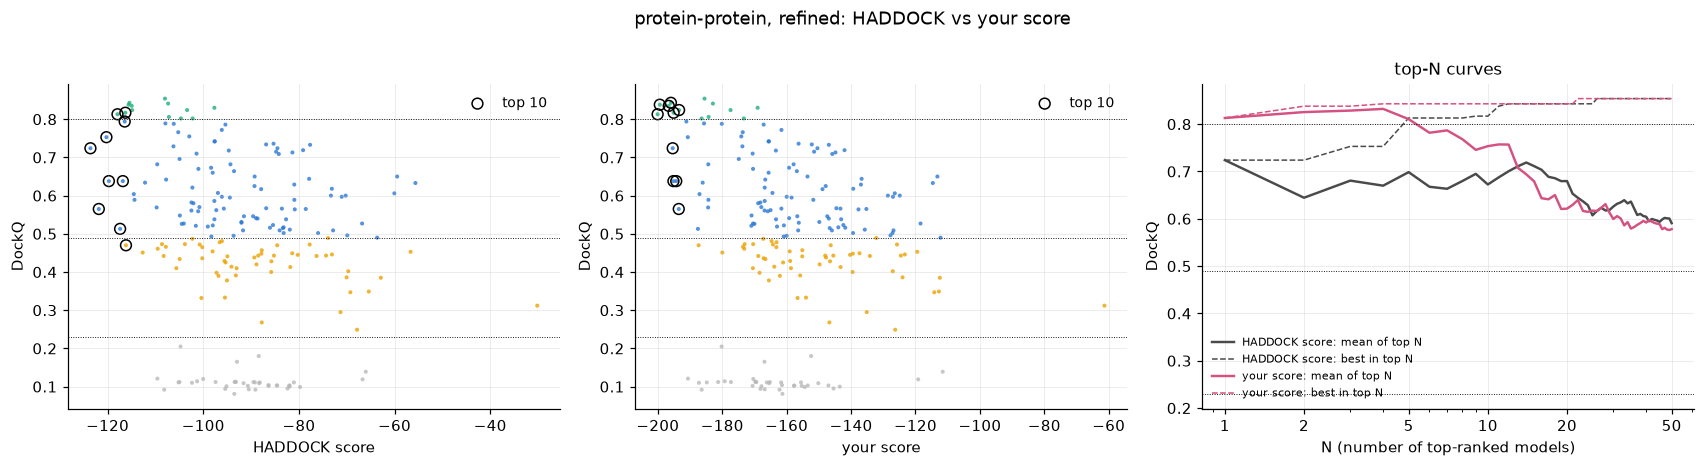

In [17]:
if not (ex1_ok and ex2_ok):
    print("Not yet: complete Exercises 1 and 2 first.")
else:
    for key, mine, name in (("pp_rigid", MY_WEIGHTS_RIGID, "rigid body"),
                            ("pp_refined", MY_WEIGHTS_REFINE, "refined")):
        d = DATA[key]
        s_mine = haddock_score(d, mine)
        print_table([("HADDOCK score", d["score"], d["dockq"]), ("your score", s_mine, d["dockq"])],
                    f"protein-protein, {name} ({len(d['dockq'])} models)")
        gain = rank_quality(s_mine, d["dockq"]) - rank_quality(d["score"], d["dockq"])
        print(f"   -> your RQ10 is {gain:+.3f} compared with HADDOCK\n")
    ranking_figure([("HADDOCK score", DATA["pp_refined"]["score"], DATA["pp_refined"]["dockq"]),
                    ("your score", haddock_score(DATA["pp_refined"], MY_WEIGHTS_REFINE),
                     DATA["pp_refined"]["dockq"])], "protein-protein, refined: HADDOCK vs your score")

**(a)** Did you beat the HADDOCK score for the rigid-body models? For the refined ones? By how much?

**(b)** Which changes helped, and which made things worse? Can you explain why, using the figures of §4 and §7?

**(c)** How confident are you that your weights would also work better on the *next* docking run?
Keep your answer — §9 puts it to the test.

<details open>
<summary><b>Exercise 3 — example solution</b></summary>

There is no single answer; here is one example.

* **Rigid body:** `{"vdw": 0.0, "elec": 1.0, "desolv": 0.3, "air": 0.05, "bsa": 0.0}` — van der Waals and BSA
  off, desolvation down, restraints up — raises $\text{RQ}_{10}$ from 0.375 to 0.442 and puts a **medium**
  model (DockQ 0.54) at rank 1 instead of an acceptable one. The reasoning: $E_\text{vdW}$ rewards the
  *wrong* models in rigid body (§4: it correlates positively with DockQ), and $E_\text{elec}$ gave the best
  top 10 of all single terms (§6).
* **Refined:** only adding a small BSA term, `"bsa": -0.05`, to HADDOCK's refinement weights raises
  $\text{RQ}_{10}$ from 0.680 to 0.795, and the mean DockQ of the top 10 from 0.672 to 0.754.

**(c)** A large gain from one small change, on one set of 200 models, should make you suspicious rather than
happy. §9 puts it to the test.
</details>

---
## **9. Let the computer search — and check honestly**

Trial and error is slow. The cell below lets the computer do it: `random_search` tries thousands of
random weight sets around a starting point (each weight multiplied by a random factor between 1/30
and 30, sometimes switched off; the signs are kept) and returns the set with the best **ranking quality
RQ10** — it optimises the top of the list directly, not a correlation. Scores for all weight sets are
computed at once with a matrix product.

In [18]:
def random_search(d, start, n_trials=20000, seed=1, n=10, models=None):
    """Try n_trials random weight sets around `start`; return (best weights, their RQ_n).
       models: optional array of model indices to use (default: all models)."""
    rng = np.random.default_rng(seed)
    E = np.column_stack([d[t] for t in TERMS])                  # models x terms
    dockq = d["dockq"]
    if models is not None:
        E, dockq = E[models], dockq[models]
    w0 = np.array([start[t] for t in TERMS], dtype=float)
    sign = np.array([1, 1, 1, 1, -1.0])                         # BSA counts favourably
    scale = np.where(w0 != 0, w0, sign * 0.01 * np.abs(w0).max())   # a switched-off term can come back
    factor = 10 ** rng.uniform(-1.5, 1.5, size=(n_trials, len(TERMS)))
    off = rng.random((n_trials, len(TERMS))) < 0.15
    W = np.where(off, 0.0, scale * factor)
    W[0] = w0                                                   # trial 0 = the starting weights
    # RQ_n = sum over ranks k of c_k * DockQ(rank k), with c_k = (1/n) * sum_{N=k..n} 1/N
    c = np.cumsum((1 / np.arange(1, n + 1))[::-1])[::-1] / n
    quality = np.empty(n_trials)
    for i in range(0, n_trials, 2000):                         # in chunks, to limit memory use
        S = E @ W[i:i + 2000].T                                 # models x trials: all scores at once
        top = np.argpartition(S, n, axis=0)[:n]                 # the n best models of every trial ...
        top = np.take_along_axis(top, np.argsort(np.take_along_axis(S, top, 0), 0), 0)   # ... in order
        quality[i:i + 2000] = c @ dockq[top]
    best = int(np.argmax(quality))
    return dict(zip(TERMS, W[best])), quality[best]


BEST_W = {}
if not (ex1_ok and ex2_ok):
    print("Not yet: complete Exercises 1 and 2 first.")
else:
    for key, start, name in (("pp_rigid", W_RIGID, "rigid body"), ("pp_refined", W_REFINE, "refined")):
        d = DATA[key]
        w, q = random_search(d, start)
        BEST_W[key] = w
        print(f"{name}: best weights found  " + "  ".join(f"{t} {w[t]:.3g}" for t in TERMS))
        print_table([("HADDOCK score", d["score"], d["dockq"]),
                     ("your score (Exercise 3)", haddock_score(d, MY_WEIGHTS_RIGID if key == "pp_rigid"
                                                               else MY_WEIGHTS_REFINE), d["dockq"]),
                     ("random search", haddock_score(d, w), d["dockq"])])

rigid body: best weights found  vdw 0.0202  elec 4.76  desolv 0.236  air 0.227  bsa 0


r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
your score (Exercise 3)           -0.31  -0.22  0.537  0.537  0.599   0.440  0.442     M M M
random search                     -0.21  -0.12  0.537  0.599  0.615   0.440  0.498     M M M

refined: best weights found  vdw 0.633  elec 0.205  desolv 0.643  air 0.116  bsa -0.0949


r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.27  -0.31  0.724  0.813  0.817   0.672  0.680     M H H
your score (Exercise 3)           -0.18  -0.23  0.813  0.843  0.843   0.754  0.795     H H H
random search                     -0.16  -0.21  0.838  0.843  0.843   0.761  0.811     H H H

The search "beats" HADDOCK easily, on both sets. But it has been judged on **the same models it was
tuned on**. With five weights and only 10 models at the top, a search can find weights that happen to
put a few lucky models first — a scoring function that has learnt *these* models, not docking. This is
called **overfitting**.

The honest test is **cross-validation**: split the models at random into two halves; search the
weights on one half (the *training* set) and measure them on the other half (the *test* set), which the
search has never seen. Repeat with ten different random splits.

rigid body: RQ10 on the TEST half
   split  HADDOCK  searched
       0    0.405     0.453   better
       1    0.383     0.485   better
       2    0.403     0.426   better
       3    0.375     0.382   better
       4    0.405     0.549   better
       5    0.397     0.441   better
       6    0.394     0.513   better
       7    0.431     0.450   better
       8    0.411     0.460   better
       9    0.367     0.298   worse
    mean    0.397     0.446   searched weights better in 9 of 10 splits

refined: RQ10 on the TEST half
   split  HADDOCK  searched
       0    0.704     0.741   better
       1    0.691     0.779   better
       2    0.667     0.571   worse
       3    0.668     0.681   better
       4    0.727     0.666   worse
       5    0.655     0.641   worse
       6    0.642     0.611   worse
       7    0.639     0.560   worse
       8    0.659     0.639   worse
       9    0.709     0.555   worse
    mean    0.676     0.644   searched weights better in 3 of 10 splits



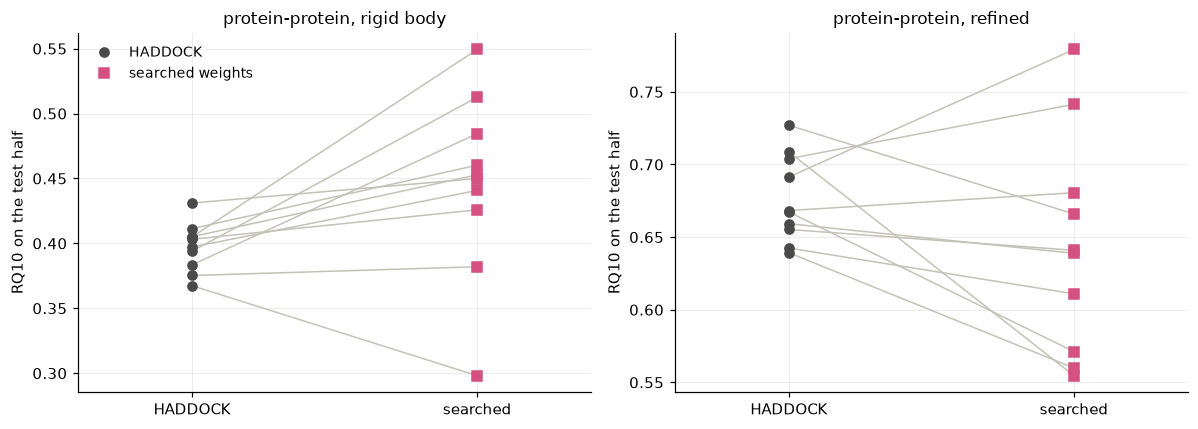

In [19]:
def cross_validate(d, start, n_splits=10, n_trials=4000, seed=7):
    """Train on a random half, test on the other half; returns (HADDOCK, searched) test RQ10, per split."""
    rng = np.random.default_rng(seed)
    n_models = len(d["dockq"])
    result = []
    for split in range(n_splits):
        perm = rng.permutation(n_models)
        train, test = perm[: n_models // 2], perm[n_models // 2:]
        w, _ = random_search(d, start, n_trials=n_trials, seed=split, models=train)
        dq = d["dockq"][test]
        result.append((rank_quality(d["score"][test], dq), rank_quality(haddock_score(d, w)[test], dq)))
    return np.array(result)


CV = {}
if not (ex1_ok and ex2_ok):
    print("Not yet: complete Exercises 1 and 2 first.")
else:
    for key, start, name in (("pp_rigid", W_RIGID, "rigid body"), ("pp_refined", W_REFINE, "refined")):
        CV[key] = cv = cross_validate(DATA[key], start)
        print(f"{name}: RQ10 on the TEST half")
        print(f"   {'split':>5} {'HADDOCK':>8} {'searched':>9}")
        for i, (h, s) in enumerate(cv):
            print(f"   {i:>5} {h:>8.3f} {s:>9.3f}   {'better' if s > h else 'worse' if s < h else 'same'}")
        print(f"   {'mean':>5} {cv[:, 0].mean():>8.3f} {cv[:, 1].mean():>9.3f}   "
              f"searched weights better in {np.sum(cv[:, 1] > cv[:, 0])} of {len(cv)} splits\n")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (key, name) in zip(axes, (("pp_rigid", "rigid body"), ("pp_refined", "refined"))):
        cv = CV[key]
        for i, (h, s) in enumerate(cv):
            ax.plot([0, 1], [h, s], "-", color="#c3c2b7", lw=1)
        ax.plot(np.zeros(len(cv)), cv[:, 0], "o", color=C_HADDOCK, label="HADDOCK")
        ax.plot(np.ones(len(cv)), cv[:, 1], "s", color=C_YOU, label="searched weights")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["HADDOCK", "searched"]); ax.set_xlim(-0.4, 1.4)
        ax.set_ylabel("RQ10 on the test half"); ax.set_title(f"protein-protein, {name}")
    axes[0].legend(loc="upper left")
    plt.tight_layout(); plt.show()

**Questions**

**(a)** Compare the in-sample gain of the random search (first table) with the gain on the test halves.
For which stage does the improvement survive cross-validation?

**(b)** Why is overfitting a bigger danger for the refined set than for the rigid-body set?

**(c)** Look at the weights the search found. Do they make physical sense? Would you trust them for a
different complex?

**(d)** HADDOCK's weights were tuned on a **benchmark of many complexes**, not on one. Why does that
matter?

<details open>
<summary><b>Section 9 — answers</b></summary>

**(a)** **Rigid body:** in-sample, the search raises $\text{RQ}_{10}$ from 0.375 to 0.498; on the test
halves the gain shrinks to 0.397 → 0.446, but the searched weights still win in **9 of 10** splits — a real,
if smaller, improvement for this complex. **Refined:** in-sample the search looks even better
(0.680 → 0.811, high-quality models at ranks 1, 5 and 10); on the test halves it is **worse** than HADDOCK
(0.644 against 0.676) and wins in only 3 of 10 splits. That gain was overfitting — and so, most likely,
was the one you found by hand in Exercise 3.

**(b)** The refined set has only 200 models, and only 13 high-quality ones: the top 10 can be filled
with different "lucky" models by small changes in the weights, and the search will find such changes.
With 1000 rigid-body models (half of them in each split), the top 10 is a smaller fraction of the set
and the signal is more robust. More data, fewer free parameters, or both, protect against overfitting.

**(c)** For the rigid-body set the search multiplied $w_\text{elec}$ by ≈5 and $w_\text{AIR}$ by ≈20,
cut $w_\text{desolv}$ to a quarter and dropped BSA: it relies on electrostatics and on the restraints. That
can make sense for *this* complex, whose restraints are good, but would be harmful for a complex with poor or
partly wrong restraints. For the refined set it kept roughly HADDOCK's weights and added a BSA term — the
change that does not survive cross-validation.

**(d)** A scoring function must work for complexes it has never seen. Weights tuned on one complex
learn the peculiarities of that complex (its size, its charges, how good its restraints are). A
benchmark of many complexes — and testing on complexes left out of the tuning — is the docking
equivalent of the cross-validation done here.
</details>

---
## **10. Exercise 4 — does your score work for other complexes?**

Everything so far was learnt from **one** complex, IIA$^\text{Glc}$–HPr. The question that matters is whether a scoring function
works for complexes it has never seen. Here are ten more protein–protein complexes, from the **Docking
Benchmark 5** (BM5), a standard test set of complexes with known structure:

> T. Vreven, I.H. Moal, A. Vangone, B.G. Pierce, P.L. Kastritis, M. Torchala, R. Chaleil, B. Jiménez-García,
> P.A. Bates, J. Fernández-Recio, A.M.J.J. Bonvin and Z. Weng. **Updates to the integrated protein–protein
> interaction benchmarks: docking benchmark version 5 and affinity benchmark version 2.**
> *J. Mol. Biol.* **427**, 3031–3041 (2015).

Each complex was docked with haddock3 starting from the **unbound** structures of the two partners (solved
separately, so their interfaces are not in the bound conformation), with restraints derived from the **true
interface**: the residues within 5 Å of the partner in the reference structure. That is the best case — in
a real prediction the restraints come from experiments or predictions and are less precise. Per complex:
1000 rigid-body models, of which the best 200 were refined (flexible refinement followed by energy
minimisation; a few did not survive). The complexes are named by their **PDB code**; look them up at
[rcsb.org](https://www.rcsb.org).

The two files `bm5-rigidbody.tsv` and `bm5-refined.tsv` are tab-separated with a normal decimal point, one
line per model: the complex, the model name, the HADDOCK score, i-RMSD, $F_\text{nat}$, L-RMSD, DockQ and the
five terms — a subset of the `capri_ss.tsv` analysis files that haddock3 writes.

In [20]:
def load_benchmark(path):
    """Read a benchmark file -> {complex: dict of arrays}, the models of each complex sorted by score."""
    lines = [line for line in Path(path).read_text().splitlines() if line.strip()]
    names = lines[0].split("\t")
    rows = [line.split("\t") for line in lines[1:]]
    out = {}
    for code in dict.fromkeys(row[0] for row in rows):         # the complexes, in file order
        sel = [row for row in rows if row[0] == code]
        d = {name: np.array([float(row[j]) for row in sel]) for j, name in enumerate(names) if j >= 2}
        order = np.argsort(d["score"], kind="stable")
        out[code] = {name: values[order] for name, values in d.items()}
    return out


BM5 = {"rigid": load_benchmark(DATA_DIR / FILES["bm5_rigid"]),
       "refined": load_benchmark(DATA_DIR / FILES["bm5_refined"])}
COMPLEXES = list(BM5["refined"])

for stage in ("rigid", "refined"):
    print(f"{stage}:  {'complex':>7} {'models':>7} {'incorrect':>10} {'acceptable':>11} {'medium':>7} {'high':>5}"
          f" {'best DockQ':>11} {'DockQ of rank 1':>16}")
    for code in COMPLEXES:
        dq = BM5[stage][code]["dockq"]
        n = np.bincount(class_of(dq), minlength=4)
        print(f"{'':8}{code:>7} {len(dq):>7} {n[0]:>10} {n[1]:>11} {n[2]:>7} {n[3]:>5} {dq.max():>11.3f} {dq[0]:>16.3f}")
    print()

rigid:  complex  models  incorrect  acceptable  medium  high  best DockQ  DockQ of rank 1
           1T6B    1000        495         428      77     0       0.648            0.443
           3WD5    1000        386         359     255     0       0.668            0.398
           2GAF    1000        503         496       1     0       0.490            0.351
           2AJF    1000        519         321     160     0       0.592            0.162
           3LVK    1000        542         225     233     0       0.558            0.414
           4LW4    1000        633         367       0     0       0.474            0.042
           5Y9J    1000        362         432     206     0       0.554            0.481
           3R9A    1000        586         414       0     0       0.466            0.122
           1HE8    1000        461         369     162     8       0.817            0.051
           1BGX    1000       1000           0       0     0       0.034            0.025

refined: 

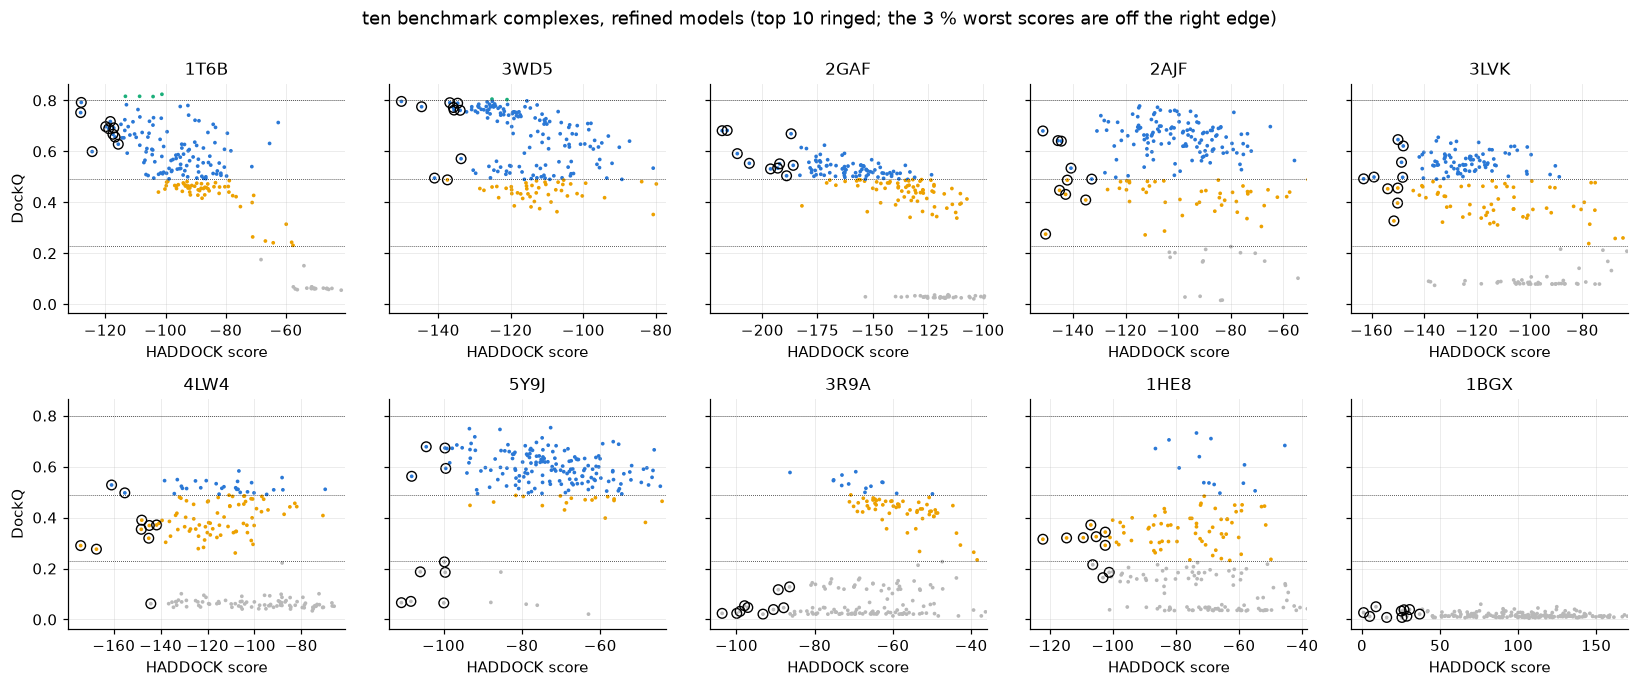

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.2), sharey=True)
for ax, code in zip(axes.flat, COMPLEXES):
    d = BM5["refined"][code]
    cls = class_of(d["dockq"])
    ax.scatter(d["score"], d["dockq"], s=6, c=[CLASS_COLOR[c] for c in cls], lw=0)
    ax.scatter(d["score"][:10], d["dockq"][:10], s=40, facecolors="none", edgecolors="k", lw=0.9)
    for t in (0.23, 0.49, 0.80):
        ax.axhline(t, color="k", lw=0.5, ls=":")
    lo, hi = d["score"].min(), np.percentile(d["score"], 97)
    ax.set_xlim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    ax.set_title(code); ax.set_xlabel("HADDOCK score")
for ax in axes[:, 0]:
    ax.set_ylabel("DockQ")
fig.suptitle("ten benchmark complexes, refined models (top 10 ringed; the 3 % worst scores are off the right edge)", y=1.0)
plt.tight_layout(); plt.show()

**(a)** Sort the ten complexes into three groups: (i) docking **succeeded** — a model of medium or high
quality is ranked first; (ii) good models were **sampled**, but the score did not put them on top — a
**scoring** failure; (iii) no acceptable model was generated at all — a **sampling** failure. Can any scoring
function help in case (iii)?

For a benchmark, the standard measure is the **success rate**: the fraction of complexes for which the top
$N$ contains at least one model of a given quality.

The function `success_rate` below computes it. It takes a **list** with one array per complex — the DockQ
values of its models, in the order of the score (best first) — and returns the fraction of complexes whose `n`
best-scored models include at least one with DockQ ≥ `threshold`. The small example shows how it works.

In [22]:
# ---------- the success rate (provided) ----------
def success_rate(ranked, n, threshold):
    """Fraction of the complexes whose top n contains a model with DockQ >= threshold.
       ranked: a list with one array per complex, the DockQ of its models in score order (best first)."""
    count = 0
    for dq in ranked:                      # one complex at a time
        if np.max(dq[:n]) >= threshold:    # the best model among its n best-scored ones
            count = count + 1
    return count / len(ranked)


# a small example: three complexes, three models each, in score order
example = [np.array([0.10, 0.50, 0.90]),   # rank 1 incorrect, rank 2 medium, rank 3 high
           np.array([0.30, 0.10, 0.10]),   # rank 1 acceptable
           np.array([0.05, 0.10, 0.20])]   # nothing acceptable at all
for n, threshold, name in ((1, 0.23, "acceptable"), (3, 0.23, "acceptable"), (3, 0.49, "medium"), (3, 0.80, "high")):
    print(f"top {n}, at least {name:10}: success rate {success_rate(example, n, threshold):.2f}")

top 1, at least acceptable: success rate 0.33
top 3, at least acceptable: success rate 0.67
top 3, at least medium    : success rate 0.33
top 3, at least high      : success rate 0.33


In [23]:
def benchmark_summary(scores, stage):
    """scores: {complex: score array} (lower = better). Returns (mean RQ10, success rates, RQ10 per complex)."""
    ranked = [top_n(scores[c], BM5[stage][c]["dockq"], len(scores[c])) for c in COMPLEXES]
    rq = np.array([rank_quality(scores[c], BM5[stage][c]["dockq"]) for c in COMPLEXES])
    rates = {(n, t): success_rate(ranked, n, t) for n in (1, 5, 10) for t in (0.23, 0.49)}
    return rq.mean(), rates, rq


def print_benchmark(rows, stage, title):
    """rows: list of (label, {complex: score array})."""
    out = []
    out.append(title)
    out.append(f"{'':34} {'mean':>6}   success rate (%) in top 1/5/10    RQ10 per complex")
    out.append(f"{'':34} {'RQ10':>6}   {'acceptable':>11} {'medium':>11}       " + " ".join(f"{c:>5}" for c in COMPLEXES)
               + "   vs HADDOCK (|diff| > 0.01)")
    ref = None
    for label, scores in rows:
        mean, rates, rq = benchmark_summary(scores, stage)
        acc = "/".join(f"{100 * rates[n, 0.23]:.0f}" for n in (1, 5, 10))
        med = "/".join(f"{100 * rates[n, 0.49]:.0f}" for n in (1, 5, 10))
        cmp = "" if ref is None else f"   better {np.sum(rq > ref + 0.01)}, worse {np.sum(rq < ref - 0.01)}"
        out.append(f"{label:34} {mean:>6.3f}   {acc:>11} {med:>11}       " + " ".join(f"{x:5.2f}" for x in rq) + cmp)
        if ref is None:
            ref = rq
    out.append("")
    show_wide("\n".join(out))


if not ex2_ok:
    print("Not yet: complete Exercise 2 first.")
else:
    for stage in ("rigid", "refined"):
        print_benchmark([("HADDOCK score", {c: BM5[stage][c]["score"] for c in COMPLEXES})], stage,
                        f"{stage}: the HADDOCK score on the ten complexes (success rates in %)")

rigid: the HADDOCK score on the ten complexes (success rates in %)
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.271      50/80/90      0/0/20        0.44  0.41  0.34  0.20  0.40  0.20  0.43  0.11  0.17  0.02

refined: the HADDOCK score on the ten complexes (success rates in %)
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.400      70/80/80    50/70/70        0.71  0.71  0.62  0.53  0.47  0.36  0.24  0.04  0.31  0.02

**(b)** What are HADDOCK's success rates at the two stages? How do they compare with the case-study complex?

**Transfer.** Now take the scoring functions you built for the case-study complex — your weights of Exercise 3
and the searched weights of §9 — and apply them, unchanged, to the ten complexes. The last column of the
table counts the complexes for which each function does better, and worse, than the HADDOCK score (by more
than 0.01 in $\text{RQ}_{10}$).

In [24]:
if not (ex1_ok and ex2_ok and BEST_W):
    print("Not yet: complete Exercises 1 and 2 and run section 9 first.")
else:
    for stage, key, mine in (("rigid", "pp_rigid", MY_WEIGHTS_RIGID), ("refined", "pp_refined", MY_WEIGHTS_REFINE)):
        rows = [("HADDOCK score", {c: BM5[stage][c]["score"] for c in COMPLEXES}),
                ("your weights (Exercise 3)", {c: haddock_score(BM5[stage][c], mine) for c in COMPLEXES}),
                ("random search (sec. 9)", {c: haddock_score(BM5[stage][c], BEST_W[key]) for c in COMPLEXES})]
        print_benchmark(rows, stage, f"{stage}: scoring functions tuned on the case-study complex")
        print("   searched weights (sec. 9):  " +
              "  ".join(f"{t} {BEST_W[key][t]:.3g}" for t in TERMS) + "\n")

rigid: scoring functions tuned on the case-study complex
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.271      50/80/90      0/0/20        0.44  0.41  0.34  0.20  0.40  0.20  0.43  0.11  0.17  0.02
your weights (Exercise 3)           0.313      60/90/90    10/40/60        0.40  0.50  0.36  0.30  0.46  0.25  0.32  0.16  0.35  0.02   better 7, worse 2
random search (sec. 9)              0.297      60/90/90    10/40/60        0.37  0.48  0.37  0.23  0.45  0.26  0.31  0.13  0.35  0.02   better 7, worse 2

   searched weights (sec. 9):  vdw 0.0202  elec 4.76  desolv 0.236  air 0.227  bsa 0



refined: scoring functions tuned on the case-study complex
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.400      70/80/80    50/70/70        0.71  0.71  0.62  0.53  0.47  0.36  0.24  0.04  0.31  0.02
your weights (Exercise 3)           0.397      60/80/80    40/70/70        0.72  0.75  0.62  0.47  0.48  0.36  0.26  0.04  0.25  0.03   better 2, worse 2
random search (sec. 9)              0.403      60/80/80    40/70/70        0.72  0.74  0.62  0.46  0.48  0.38  0.33  0.05  0.22  0.03   better 4, worse 2

   searched weights (sec. 9):  vdw 0.633  elec 0.205  desolv 0.643  air 0.116  bsa -0.0949



**(c)** Do your weights and the searched weights of §9 work on the ten benchmark complexes? Compare the mean
$\text{RQ}_{10}$, the success rates and the number of complexes for which they beat the HADDOCK score — at
each stage. Compare with what §9 told you about the same weights on the case-study complex.

**(d)** For the rigid-body models, which weight did both you and the search increase relative to the other
terms? Why would that help *on these complexes*, and would it in a real docking run? *(Hint: where do the
restraints of the benchmark runs come from?)*

**(e)** Ten complexes are enough to show you the problem. What would you need to show that a new scoring
function is really better than HADDOCK's?

<details open>
<summary><b>Exercise 4 — answers</b></summary>

**(a)** Refined models: docking **succeeded** for 1T6B, 3WD5, 2GAF, 2AJF and 3LVK (a medium or high model at
rank 1). **Scoring failures**: 5Y9J (164 medium models, but rank 1 has DockQ 0.07 and three of the top 5 are
incorrect), 3R9A (14 medium models, all of the top 10 incorrect), 4LW4 and 1HE8 (medium models sampled, an
acceptable one ranked first). 1HE8 is striking at the rigid-body stage: 8 **high**-quality models were
generated (best DockQ 0.82), yet the model ranked first is incorrect. **Sampling failure**: 1BGX — no
acceptable model at either stage (best DockQ 0.06). No scoring function can rescue it: you can only rank the
models you have.

**(b)** Rigid body: acceptable in the top 1/5/10 for 50/80/90 % of the complexes, but medium only 0/0/20 %.
Refined: acceptable 70/80/80 %, medium 50/70/70 %; mean $\text{RQ}_{10}$ rises from 0.27 to 0.40. 80 % is close to
the ceiling: 1BGX cannot succeed, and 3R9A only with a much better score. The case-study complex is one of the
successful cases (medium at rank 1 after refinement).

**(c)** **Rigid body: partly.** Your example weights and the searched weights raise the mean $\text{RQ}_{10}$ from
0.271 to 0.313 and 0.297, and the success rate for medium models in the top 5 from 0 to 40 %; both are better
for 7 complexes and worse for 2. On the case study the searched weights also survived cross-validation (§9),
so this is consistent. **Refined: no.** Your weights give 0.397 and the searched weights 0.403, against 0.400
— better for 2–4 complexes, worse for 2. The searched weights that "beat" HADDOCK so clearly on the case study
(§9: 0.811 against 0.680) are worth nothing elsewhere — exactly what the cross-validation of §9 predicted.

**(d)** Relative to the other terms, both put more weight on the **restraints**: your example weights switch
off van der Waals and BSA and multiply $w_\text{AIR}$ by 5; the search multiplies $w_\text{AIR}$ by ≈20. That helps
here because the benchmark runs used restraints taken from the **true interface**: satisfying them *is* being
right. In a real docking run restraints come from mutagenesis, NMR, cross-links or predictions, and are
incomplete or partly wrong; a score that trusts them blindly ranks first the models that satisfy wrong
restraints. The conditions under which a scoring function is tuned must be the conditions under which it will
be used.

**(e)** Many more complexes (the docking benchmark has more than 200, of different types and difficulty),
docked under realistic conditions (several restraint scenarios, including noisy and ab initio ones);
tuning on some complexes and validating on others that were not used, plus a final test set that is not used
for any choice; success rates with **error bars** (with ten complexes, one complex is 10 % of the success
rate); and an improvement that is consistent across complexes, not driven by one or two. The follow-up
notebook `Docking-scoring-optimisation` does the first step: tuning on nine complexes and testing on the tenth.
</details>

---
## **11. Take-home messages**

* **Scoring is the bottleneck of docking.** Good models are usually generated; the problem is to put
  them at the top. The HADDOCK score does this well at the level that matters — the top 1–10 contain
  acceptable (rigid body) to medium/high-quality (refined) models — while its correlation with DockQ over
  all models is only moderate.
* **Correlation is not ranking.** A correlation coefficient weighs every model equally, including hundreds
  of bad models nobody will look at. What counts is the quality of the **top-ranked** models: top-1/5/10
  success and CAPRI classes.
* **Weights depend on the stage.** Rigid-body models clash, so van der Waals is down-weighted; after
  refinement packing becomes meaningful. A scoring function is tuned for the models it has to rank.
* **Beating a scoring function on one set of models is easy — and means little.** A search over five weights
  readily finds a better top 10 on the models it was tuned on. Cross-validation shows how much of that
  survives on unseen models: some in rigid body, nothing after refinement — that was overfitting.
* **One complex is not a benchmark.** Weights tuned on the case study help a little on ten other complexes in
  rigid body — partly because the benchmark's restraints are unrealistically good — and not at all after
  refinement. A scoring function must be optimised on a **large and diverse set of complexes**, validated on
  complexes left out of the optimisation, under realistic conditions. That is how HADDOCK's weights were
  obtained, and why they are hard to beat.
* **Scoring cannot fix sampling.** When no acceptable model was generated (1BGX), every scoring function
  fails. Docking success is the product of both steps, and a benchmark success rate measures both.

**Next:** the notebook **`Docking-scoring-optimisation`** asks whether normalising the terms or machine
learning gives a better score, and optimises on several complexes at once.

## **Going further**

Open-ended, no scaffolding provided:

* **Other criteria.** Search for weights that maximise the top-1 DockQ, or the number of medium models in the
  top 5, instead of $\text{RQ}_{10}$. Do you get the same weights? Which criterion overfits more?
* **i-RMSD instead of DockQ.** Redo §6 with the i-RMSD (lower = better) as the quality measure. Do the
  conclusions change?
* **Weights for one complex.** Run `random_search` on one of the benchmark complexes (`BM5["refined"]["5Y9J"]`)
  and apply the weights to the case study. Does a complex where HADDOCK fails teach a better score?